<a href="https://colab.research.google.com/github/VarshaSpoorthi-shree/ComputerVision/blob/main/1RUA24CSE0517_CV_LAB_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install opencv-python numpy matplotlib scikit-image

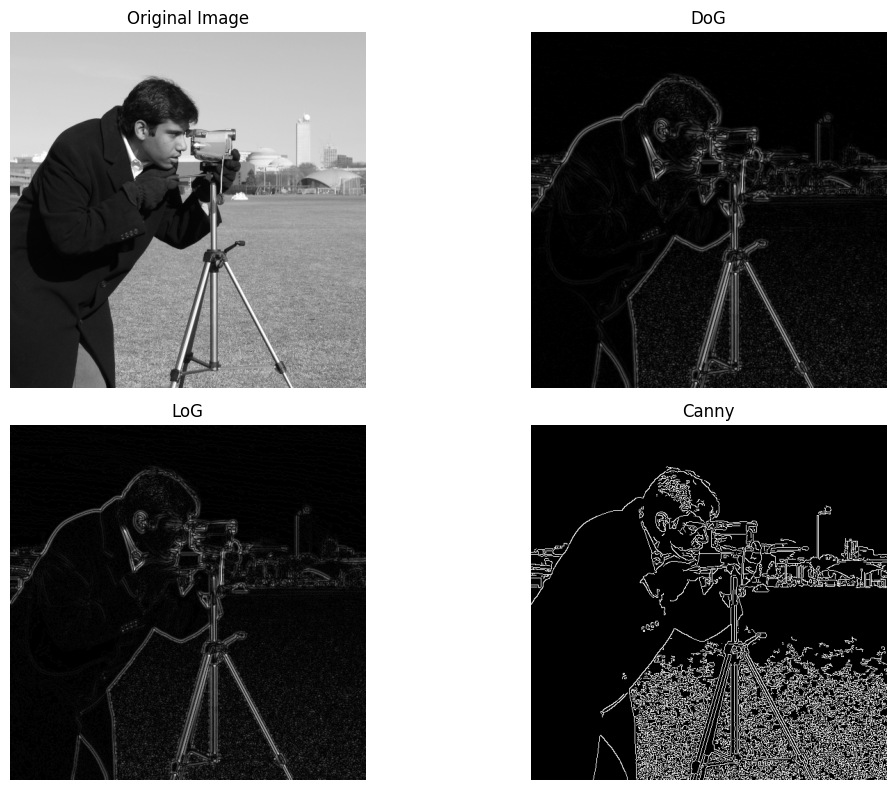

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype(np.uint8)

# ---------------- DoG ----------------
sigma1 = 1.0
sigma2 = 2.0

g1 = cv2.GaussianBlur(image, (0, 0), sigma1)
g2 = cv2.GaussianBlur(image, (0, 0), sigma2)

dog = cv2.absdiff(g1, g2)
dog_display = cv2.normalize(
    dog, None, 0, 255, cv2.NORM_MINMAX
)

# ---------------- LoG ----------------
sigma = 1.2
blur = cv2.GaussianBlur(image, (0, 0), sigma)

laplacian = cv2.Laplacian(blur, cv2.CV_64F)
log_display = cv2.normalize(
    np.abs(laplacian), None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# ---------------- Canny ----------------
low_threshold = 50
high_threshold = 150

canny = cv2.Canny(
    image, low_threshold, high_threshold
)

# ---------------- Display ----------------
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(dog_display, cmap="gray")
plt.title("DoG")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(log_display, cmap="gray")
plt.title("LoG")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny, cmap="gray")
plt.title("Canny")
plt.axis("off")

plt.tight_layout()
plt.show()


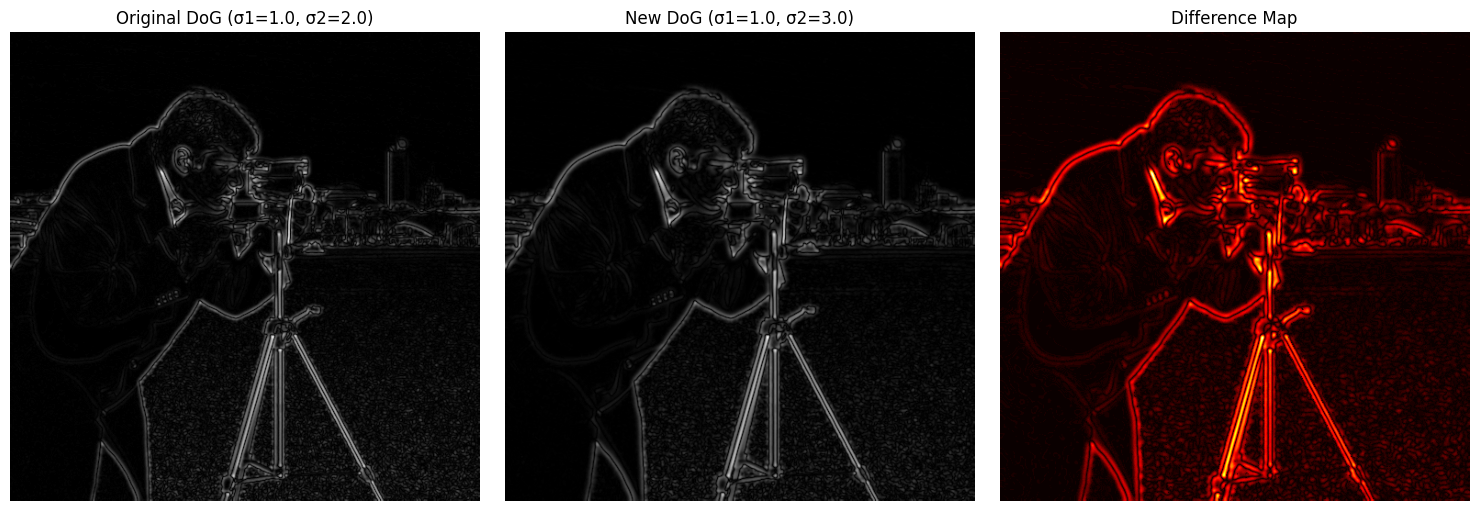

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Keep the original DoG results for comparison
dog_original = dog.copy()

# ---------------- New DoG (sigma1 = 1.0, sigma2 = 3.0) ----------------
new_sigma1 = 1.0
new_sigma2 = 3.0

g1_new = cv2.GaussianBlur(image, (0, 0), new_sigma1)
g2_new = cv2.GaussianBlur(image, (0, 0), new_sigma2)

dog_new = cv2.absdiff(g1_new, g2_new)
dog_new_display = cv2.normalize(
    dog_new, None, 0, 255, cv2.NORM_MINMAX
)

# ---------------- Record the Difference ----------------
# Compute pixel-wise difference between the two DoG results
dog_diff = cv2.absdiff(dog_original, dog_new)
dog_diff_display = cv2.normalize(
    dog_diff, None, 0, 255, cv2.NORM_MINMAX
)

# ---------------- Display Comparison ----------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(dog_display, cmap="gray")
plt.title("Original DoG (σ1=1.0, σ2=2.0)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(dog_new_display, cmap="gray")
plt.title("New DoG (σ1=1.0, σ2=3.0)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dog_diff_display, cmap="hot")
plt.title("Difference Map")
plt.axis("off")

plt.tight_layout()
plt.show()

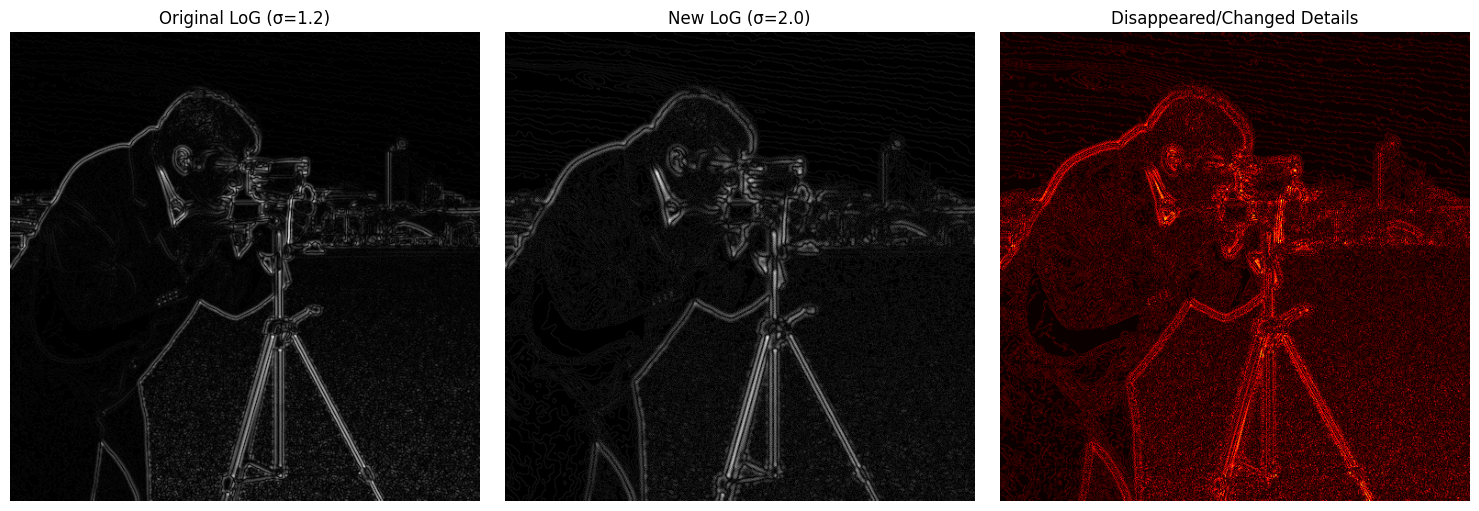

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Keep original LoG results from the previous state for comparison
log_original = log_display.copy()

# ---------------- New LoG (sigma = 2.0) ----------------
new_sigma_log = 2.0
blur_new = cv2.GaussianBlur(image, (0, 0), new_sigma_log)
laplacian_new = cv2.Laplacian(blur_new, cv2.CV_64F)
log_new_display = cv2.normalize(
    np.abs(laplacian_new), None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# ---------------- Difference to highlight disappeared details ----------------
# A simple absolute difference shows where high-frequency fine details are lost/altered
log_diff = cv2.absdiff(log_original, log_new_display)

# ---------------- Display Comparison ----------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(log_original, cmap="gray")
plt.title("Original LoG (σ=1.2)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(log_new_display, cmap="gray")
plt.title("New LoG (σ=2.0)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(log_diff, cmap="hot")
plt.title("Disappeared/Changed Details")
plt.axis("off")

plt.tight_layout()
plt.show()

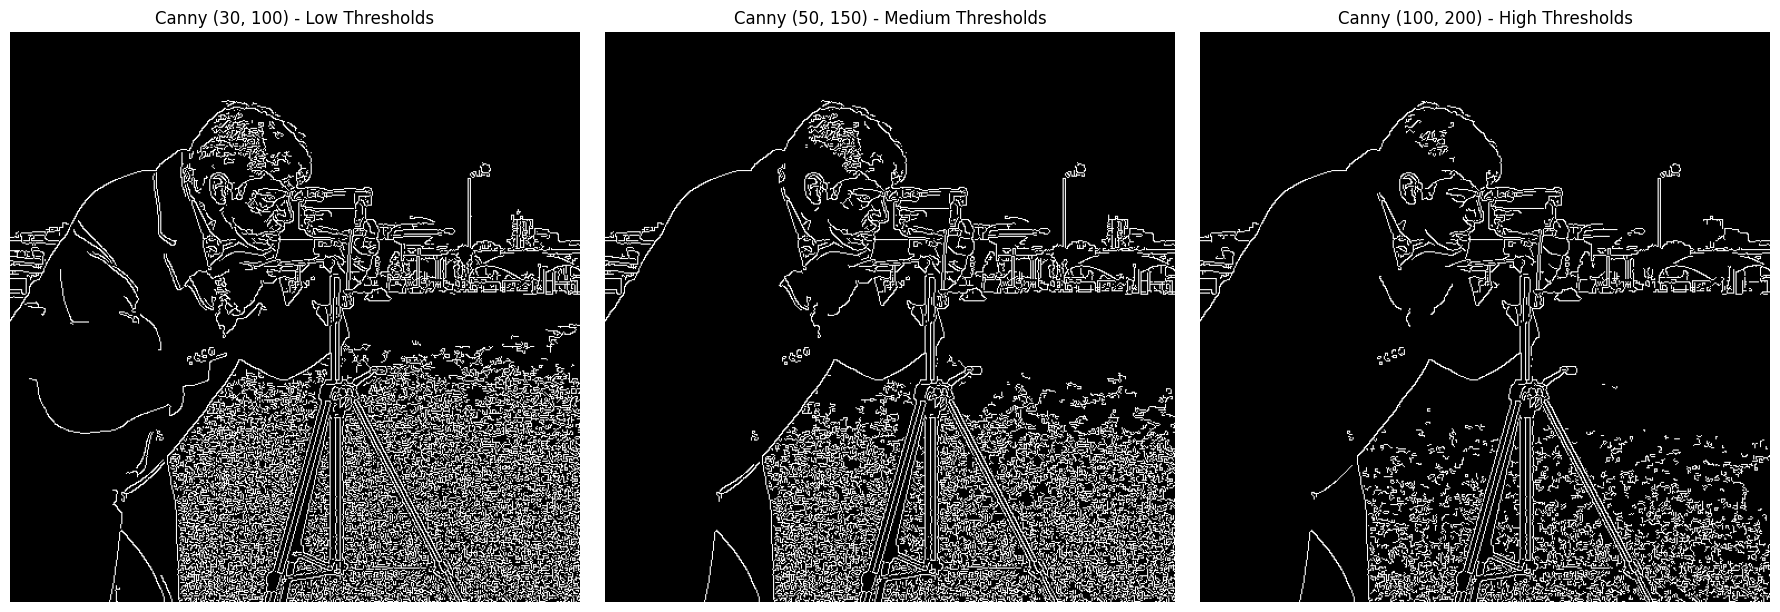

In [5]:
import cv2
import matplotlib.pyplot as plt

# Run Canny with the requested threshold configurations
canny_1 = cv2.Canny(image, 30, 100)
canny_2 = cv2.Canny(image, 50, 150) # This matches the original threshold set
canny_3 = cv2.Canny(image, 100, 200)

# Plot the three outputs for comparison
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(canny_1, cmap="gray")
plt.title("Canny (30, 100) - Low Thresholds")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_2, cmap="gray")
plt.title("Canny (50, 150) - Medium Thresholds")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_3, cmap="gray")
plt.title("Canny (100, 200) - High Thresholds")
plt.axis("off")

plt.tight_layout()
plt.show()

Observations Comparing DoG, LoG, and Canny Edge Detection
Sensitivity to Noise and Texture:

Canny edge detection is highly structured and binary, but at lower thresholds, it gets extremely cluttered by the high-frequency texture of the grassy field.
DoG and LoG produce soft, grayscale gradient-like representations that inherently suppress or naturally blend texture noise rather than outputting hard, noisy binary pixel connections.
Edge Thickness and Continuity:

Canny utilizes non-maximum suppression followed by hysteresis thresholding, which forces all detected edges to be crisp, thin, single-pixel-wide continuous contours.
DoG and LoG do not perform non-maximum suppression; instead, they output broader, thicker bandpass intensity sweeps that widen as you increase the Gaussian smoothing scale ($\sigma$$\sigma$).
Parameter Tunability and Behavior:

In DoG and LoG, the scales ($\sigma$$\sigma$) act as scale-space controls. Adjusting them determines exactly what frequency level (fine textures vs. broad structural outlines) gets filtered and retained.
In Canny, the thresholds determine edge connectivity and strength. While the underlying Gaussian filter controls the scale, the dual thresholds directly control which weak edges are connected to strong ones, creating a cleaner binary sketch of the scene.

Why Gaussian Smoothing is Essential Before Derivative-Based Edge Detection
Derivative-based edge detectors (like Laplacian, Sobel, or the gradient calculations in Canny) identify edges by finding areas in an image where intensity changes rapidly—which mathematically corresponds to high values in the first derivative or zero-crossings in the second derivative.

However, differentiation is a high-pass filtering operation. Here is why smoothing with a Gaussian filter beforehand is critical:

Noise Amplification Suppression: Noise in an image consists of rapid, high-frequency pixel intensity fluctuations. Taking the derivative of these fluctuations multiplies their amplitude significantly, creating false edges everywhere. Gaussian smoothing acts as a low-pass filter, removing these high-frequency components so that the derivative highlights actual structural boundaries rather than random pixel noise.

Scale-Space Control: By adjusting the size of the Gaussian kernel (defined by $\sigma$$\sigma$), you can control the scale of the edges you wish to detect. A smaller $\sigma$$\sigma$ preserves fine details and detects thin, localized edges, whereas a larger $\sigma$$\sigma$ filters out minor details to capture only major, coarse structural boundaries.

Smoothing the Gradient Vector Field: For detectors like Canny that rely on gradient direction to perform non-maximum suppression, pre-smoothing ensures that the computed directions of the gradient vectors vary smoothly across edge boundaries rather than pointing in chaotic directions due to local textures.

### Observation Summary Table

| Method | Edge Thickness | Noise Sensitivity | Continuity | Remarks |
| :--- | :--- | :--- | :--- | :--- |
| **DoG** | Broad and variable. Edge thickness scales directly with the difference between $\sigma_1$ and $\sigma_2$. | Moderate. The dual Gaussian blur steps suppress high-frequency noise, but some texture still passes through depending on the scale settings. | Grayscale gradients rather than thin binary lines. Soft, shaded contours that don't enforce absolute structural continuity. | Acts as an efficient bandpass filter. Excellent for simulating biological vision systems and isolating specific frequency bands. |
| **LoG** | Thick and blurry. The edges are represented by zero-crossings, but the output scale/width increases directly with the smoothing parameter $\sigma$. | Low to Moderate. Highly adjustable by changing $\sigma$; fine noise disappears completely under larger smoothing scales. | Grayscale zero-crossing transitions. Boundaries are soft, representing gradual intensity changes rather than sharp, discrete edges. | An isotropic (direction-independent) second-derivative operator that is highly effective for scale-space representation. |
| **Canny** | Thin and sharp. Enforces a single-pixel-wide line through non-maximum suppression. | Highly dependent on thresholds. Low thresholds preserve heavy noise/textures (like the grass), while high thresholds isolate clean structural boundaries. | Extremely high. Uses dual-threshold hysteresis tracking to connect weak edge pixels to strong edge pixels, forming clean, continuous contours. | A highly optimized, multi-stage edge detector. Ideal for computer vision applications requiring clean, isolated structural outlines.